# Evaluation dataset exploration

Inspect the supplied data without training on references or hypotheses. Normalization and validation come from the shared package.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from asr_rescoring.config import load_config, resolve_path
from asr_rescoring.dataset import load_dataset
from asr_rescoring.preprocessing import normalize_text

config = load_config()
records = load_dataset(resolve_path(config, "evaluation"))
frame = pd.DataFrame(
    [
        {
            "utt_id": r.utt_id,
            "reference_words": len(normalize_text(r.reference).split()),
            "candidates": len(r.hypotheses),
            "unique_normalized_candidates": len(set(map(normalize_text, r.hypotheses))),
            "reference_available": normalize_text(r.reference)
            in list(map(normalize_text, r.hypotheses)),
        }
        for r in records
    ]
)
frame.describe(include="all")

,utt_id,reference_words,candidates,unique_normalized_candidates,reference_available
count,500,500.000000,500.0,500.000000,500
unique,500,NaN,NaN,NaN,1
top,ua_title_0000,NaN,NaN,NaN,True
freq,1,NaN,NaN,NaN,500
mean,NaN,9.208000,8.0,7.766000,NaN
std,NaN,2.703952,0.0,0.423796,NaN
min,NaN,4.000000,8.0,7.000000,NaN
25%,NaN,7.000000,8.0,8.000000,NaN
50%,NaN,9.000000,8.0,8.000000,NaN
75%,NaN,11.000000,8.0,8.000000,NaN


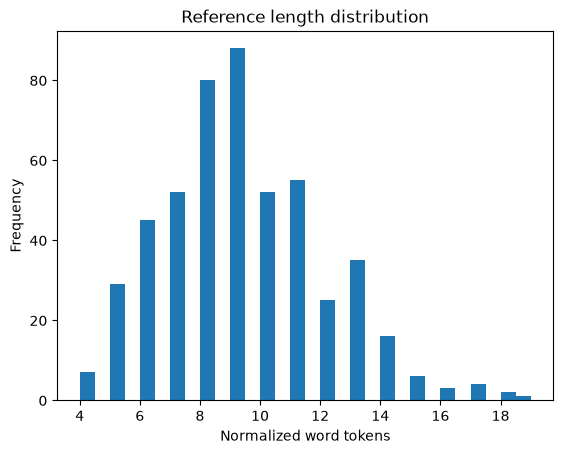

,utt_id,reference_words,candidates,unique_normalized_candidates,reference_available
0,ua_title_0000,4,8,8,True
1,ua_title_0001,6,8,8,True
2,ua_title_0002,9,8,8,True
3,ua_title_0003,10,8,8,True
4,ua_title_0004,9,8,8,True
5,ua_title_0005,11,8,8,True
6,ua_title_0006,6,8,7,True
7,ua_title_0007,13,8,8,True
8,ua_title_0008,11,8,8,True
9,ua_title_0009,7,8,8,True


In [2]:
frame["reference_words"].plot.hist(bins=30, title="Reference length distribution")
plt.xlabel("Normalized word tokens")
plt.show()
frame.head(10)

Corpus preparation metadata contains actual token counts and domain contributions. Inspect it after preparation.

In [3]:
import json

manifest_path = resolve_path(config, "processed_corpus").with_suffix(".json")
if manifest_path.exists():
    preparation = json.loads(manifest_path.read_text(encoding="utf-8"))
    display(pd.DataFrame(preparation["subsets"]))
else:
    print("Prepare corpus first; no preparation statistics are fabricated.")

,budget,actual_tokens,sentences,domain_sentences,domain_tokens,filename,sha256
0,100000,99987,5030,"{'court': 1008, 'fiction': 1007, 'news': 1001,...","{'court': 39351, 'fiction': 12981, 'news': 161...",tokens_100000.txt,27e885525b32504bcce68e77d3b1d36f2c65b127a6c904...
1,1000000,999999,49975,"{'court': 10011, 'fiction': 10002, 'news': 995...","{'court': 397960, 'fiction': 125800, 'news': 1...",tokens_1000000.txt,a06757cdcdfd61af8b488e3f46eb33e36ff130ba42426d...
2,10000000,9999984,500646,"{'court': 100284, 'fiction': 100205, 'news': 9...","{'court': 3998102, 'fiction': 1249427, 'news':...",tokens_10000000.txt,d151addcb8912b87bdf8e99c4e851d6c45903167a5c605...
